# Ageing clock benchmark

Runs six published epigenetic clocks on a public blood-methylation dataset with [Biolearn](https://bio-learn.github.io/) and asks:

1. How well does each clock track chronological age?
2. Do the clocks agree on who is ageing fast?
3. Do they register schizophrenia, a condition linked to shorter life?
4. Does that signal survive adjustment for smoking and blood cell composition?

Three whole-blood 450K cohorts of schizophrenia and controls can be run. Set `DATASET` below, or the `CLOCK_DATASET` environment variable:

| Dataset | Cases / controls | Loaded by |
| --- | --- | --- |
| GSE41169 | 62 / 33 | Biolearn's data library (part 1) |
| GSE80417 | 353 / 322 | this project's loader: the betas are only in a GEO supplementary file |
| GSE84727 | 414 / 433 | the same loader; deposited without about 65,000 probes, including all sex-chromosome probes |

Section 9 reruns the clocks on only GSE84727's probes, to measure how much that filtering changes each clock. Outputs go to `results/<DATASET>/`. The framing follows Moqri et al. 2023 (*Cell*, [doi:10.1016/j.cell.2023.08.003](https://doi.org/10.1016/j.cell.2023.08.003)); interpretation is in `WRITEUP.md`.

In [1]:
# ---- Settings ---------------------------------------------------------------
import os
DATASET = os.environ.get("CLOCK_DATASET", "GSE41169")

# Samples excluded in the QC-passed analysis, besides sex mismatches (see section 4)
DATASETS = {
    "GSE41169": {"exclude": ["GSM1009696"]},  # four clocks put it 14-21 years below its recorded age
    "GSE80417": {"exclude": []},
    "GSE84727": {"exclude": []},
}
MANUAL_EXCLUDE = DATASETS[DATASET]["exclude"]

# Recorded ages outside this range are data-entry errors (GSE80417 has one of 891) and are
# treated as missing: one such value distorts every age regression in the cohort.
AGE_RANGE = (0, 110)

# label -> (Biolearn model name, kind). "age" = biological age in years, "pace" = rate of ageing.
CLOCKS = {
    "Horvath":     ("Horvathv1",   "age"),   # trained on chronological age
    "Hannum":      ("Hannum",      "age"),   # trained on chronological age
    "PhenoAge":    ("PhenoAge",    "age"),   # trained on a clinical phenotype
    "GrimAge2":    ("GrimAgeV2",   "age"),   # trained on time to death
    "DunedinPACE": ("DunedinPACE", "pace"),  # trained on pace of physiological decline
    "CausAge":     ("YingCausAge", "age"),   # CpGs with putative causal links to ageing
}
# CpGs a model needs but the data lacks are filled from Biolearn's 450K reference medians.
# ("averaging" fills only missing values of CpGs that are present: linear clocks then fail on
# absent CpGs, and GrimAge2 silently drops them.)
IMPUTATION = "sesame_450k"

# Rerun the clocks on only this dataset's probes (section 9); None to skip
SENSITIVITY_PROBES = "GSE84727"

# Metadata coding, the same for all three datasets
CONDITION_COL = "disease"
CONDITION_LABELS = {1.0: "control", 2.0: "schizophrenia"}
CASE, CONTROL = "schizophrenia", "control"
SEX_LABELS = {1: "Male", 0: "Female"}
# Run the methylation sex check only if this share of the estimator's probes is present
SEX_CHECK_MIN = {"X": 0.5, "Y": 0.1}

RESULTS_DIR = f"../results/{DATASET}"

In [2]:
import gc, sys, platform, subprocess, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, str(Path("../src").resolve()))
from clockbench import clock_metrics, compare_groups, deviation_correlations, deviation_table
from clockbench.biolearn_io import (available_models, find_column, load_dataset, model_cpgs, resolve_names,
                                    run_clocks, sex_probe_coverage, subset_cpgs, subset_samples)
from clockbench.geo_supplementary import probe_ids
from clockbench.plots import (apply_style, plot_adjustment_effect, plot_deviation_heatmap,
                              plot_group_forest, plot_predicted_vs_age)

import biolearn
from biolearn.model_gallery import ModelGallery

apply_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 20)
out = Path(RESULTS_DIR)
out.mkdir(parents=True, exist_ok=True)
gallery = ModelGallery()

print("Dataset", DATASET, "| Python", platform.python_version(), "| Biolearn", getattr(biolearn, "__version__", "unknown"))

Dataset GSE80417 | Python 3.11.18 | Biolearn 0.9.1


## 1. Clocks

In [3]:
models = available_models()
print(f"{len(models)} models in this Biolearn version")

wanted = {label: name for label, (name, _) in CLOCKS.items()}
resolved, missing = resolve_names(list(wanted.values()), models)
for name, close in missing.items():
    print(f"  not found: {name}. Close matches: {close or 'none'}")

clock_names = {label: resolved[name] for label, name in wanted.items() if name in resolved}
kinds = {label: CLOCKS[label][1] for label in clock_names}
print("Will run:", clock_names)

68 models in this Biolearn version
Will run: {'Horvath': 'Horvathv1', 'Hannum': 'Hannum', 'PhenoAge': 'PhenoAge', 'GrimAge2': 'GrimAgeV2', 'DunedinPACE': 'DunedinPACE', 'CausAge': 'YingCausAge'}


## 2. Data

The first run downloads the data from GEO and caches it in the project folder. Samples without a usable recorded age are dropped here: every comparison uses age deviation, and GrimAge2 takes age as an input.

In [4]:
t0 = time.perf_counter()
data = load_dataset(DATASET)
print(f"Loaded in {time.perf_counter() - t0:.0f} s")

AGE_COL = find_column(data.metadata, "age")
SEX_COL = find_column(data.metadata, "sex", "gender")
recorded_age = pd.to_numeric(data.metadata[AGE_COL], errors="coerce")
implausible = recorded_age[(recorded_age < AGE_RANGE[0]) | (recorded_age > AGE_RANGE[1])]
for sample, value in implausible.items():
    print(f"Recorded age {value:g} for {sample} is outside {AGE_RANGE}: treated as missing")
no_age = recorded_age.index[recorded_age.isna()].union(implausible.index)
if len(no_age):
    by_group = data.metadata.loc[no_age, CONDITION_COL].map(CONDITION_LABELS).value_counts().to_dict()
    print(f"Dropped {len(no_age)} samples without a usable age: {by_group}")
    data = subset_samples(data, data.metadata.index.difference(no_age))

meta, dnam = data.metadata.copy(), data.dnam
meta[CONDITION_COL] = meta[CONDITION_COL].map(CONDITION_LABELS)
age = pd.to_numeric(meta[AGE_COL], errors="coerce")
sex01 = meta[SEX_COL].astype(float).rename("sex")
groups = meta[CONDITION_COL].astype("string")
group_order = [CONTROL, CASE]

print(f"Methylation matrix: {dnam.shape[0]:,} CpGs x {dnam.shape[1]} samples")
print(f"Missing beta values per sample: median {dnam.isna().mean().median():.2%}, max {dnam.isna().mean().max():.2%}")
print(f"Age: {age.min():.0f}-{age.max():.0f} y, median {age.median():.0f}\n")

summary_tbl = pd.DataFrame({
    "n": groups.value_counts(),
    "median age": age.groupby(groups).median(),
    "male (%)": (meta[SEX_COL].map(SEX_LABELS) == "Male").groupby(groups).mean().mul(100).round(0),
}).loc[group_order]
summary_tbl

GSE80417: disease code vs source name
disease status    1    2
source_name             
case blood        0  353
control blood   322    0

{'cpgs': 483636, 'samples': 675, 'missing_fraction': 0.0, 'min': 0.0011, 'max': 0.9945}
Loaded in 6 s
Recorded age 891 for GSM2126406 is outside (0, 110): treated as missing
Recorded age 883 for GSM2126750 is outside (0, 110): treated as missing
Dropped 39 samples without a usable age: {'schizophrenia': 21, 'control': 18}


Methylation matrix: 483,636 CpGs x 636 samples


Missing beta values per sample: median 0.00%, max 0.00%
Age: 18-90 y, median 37



,n,median age,male (%)
disease,,,
control,304,31.0,44.0
schizophrenia,332,42.0,73.0


## 3. Run the clocks

In [5]:
# Every model reads only its own CpGs (plus DunedinPACE's normalisation set), so the models run on
# just those rows: the same results as on the full matrix, with a fraction of the memory.
model_input = subset_cpgs(data, model_cpgs(gallery, list(clock_names.values()) + ["SmokingMcCartney", "DeconvoluteBlood450K"]))
print(f"Model input: {model_input.dnam.shape[0]:,} CpGs x {model_input.dnam.shape[1]} samples")

run = run_clocks(model_input, clock_names, imputation=IMPUTATION)
for label, secs in run.seconds.items():
    print(f"  {label:<12} ok      {secs:5.1f} s")
for label, err in run.failed.items():
    print(f"  {label:<12} FAILED  {err[:160]}")

preds = run.predictions
kinds = {k: v for k, v in kinds.items() if k in preds.columns}

# Age deviation: residual of each clock regressed on chronological age.
# Removes each clock's offset and age bias, so deviations are comparable across clocks.
dev = deviation_table(preds, age)
dev.to_csv(out / "age_deviation_per_sample.csv")
preds.describe().T

Model input: 22,975 CpGs x 636 samples


  Horvath      ok        0.2 s
  Hannum       ok        0.2 s
  PhenoAge     ok        0.2 s
  GrimAge2     ok        0.6 s
  DunedinPACE  ok        2.9 s
  CausAge      ok        0.2 s


,count,mean,std,min,25%,50%,75%,max
Horvath,636.0,41.314,12.417,12.316,31.489,39.866,49.904,85.985
Hannum,636.0,47.410,12.994,21.749,36.974,45.355,56.245,97.312
PhenoAge,636.0,38.620,13.943,1.137,27.894,36.789,47.981,84.437
GrimAge2,636.0,56.526,13.401,30.653,44.966,55.618,66.043,99.649
DunedinPACE,636.0,1.061,0.148,0.687,0.953,1.049,1.161,1.524
CausAge,636.0,42.868,12.719,18.079,32.828,41.506,51.375,91.437


## 4. Sample QC

Two checks before any group comparison:

- **Sex check.** Methylation-predicted sex against recorded sex. A mismatch means the metadata for that sample can't be trusted. It needs the estimator's X and Y probes, so it is skipped for GSE84727, which was deposited without them.
- **Age outliers.** A sample flagged by several independent clocks at once points to a sample-level problem (e.g. a wrongly recorded age) rather than biology. Exclusions are set per dataset in `DATASETS`.

In [6]:
coverage = sex_probe_coverage(dnam)
print("Sex-estimator probes present: " + ", ".join(f"{k} {v:.0%}" for k, v in coverage.items()))
qc = meta.copy()
qc["recorded_sex"] = qc[SEX_COL].map(SEX_LABELS)

if all(coverage[k] >= SEX_CHECK_MIN[k] for k in SEX_CHECK_MIN):
    qc = gallery.get("SexEstimation").predict(data).join(qc)
    sex_mismatch = qc.index[qc["predicted_sex"] != qc["recorded_sex"]].tolist()
    print(f"Sex mismatches: {len(sex_mismatch)} of {len(qc)}")
    display(pd.crosstab(qc["recorded_sex"], qc["predicted_sex"]))
    display(qc.loc[sex_mismatch, ["X", "Y", "predicted_sex", "recorded_sex", AGE_COL, CONDITION_COL]].join(dev.round(1)))
else:
    sex_mismatch = []
    qc["predicted_sex"] = np.nan
    print("Sex check skipped: too few of the estimator's X/Y probes in this dataset")

# Nothing below needs the full matrix
del data, dnam
gc.collect();

Sex-estimator probes present: X 99%, Y 24%


Sex mismatches: 0 of 636


predicted_sex,Female,Male
recorded_sex,,
Female,259,0
Male,0,377


,X,Y,predicted_sex,recorded_sex,age,disease,Horvath,Hannum,PhenoAge,GrimAge2,DunedinPACE,CausAge


In [7]:
# Most negative age deviation per clock: one sample dominating several clocks is suspicious
extremes = pd.DataFrame({"sample": dev.idxmin(), "deviation": dev.min().round(1)})
display(extremes)

if MANUAL_EXCLUDE:
    print("Recorded data and deviations for the manually excluded samples:")
    display(qc.loc[MANUAL_EXCLUDE, ["predicted_sex", "recorded_sex", AGE_COL, CONDITION_COL]].join(dev.round(1)))

qc_fail = sex_mismatch + [s for s in MANUAL_EXCLUDE if s not in sex_mismatch]
qc_pass = meta.index.difference(qc_fail)
print(f"QC-passed samples: {len(qc_pass)} (excluded: {', '.join(qc_fail) or 'none'})")

,sample,deviation
Horvath,GSM2126317,-19.6
Hannum,GSM2126294,-16.4
PhenoAge,GSM2126902,-21.2
GrimAge2,GSM2126462,-13.6
DunedinPACE,GSM2126476,-0.3
CausAge,GSM2126924,-14.5


QC-passed samples: 636 (excluded: none)


## 5. Agreement with chronological age, and between clocks

Tracking chronological age closely is context, not the goal: a near-perfect age predictor says little about health (the "paradox of biomarkers"). The heatmap asks whether clocks rank the same people as fast agers.

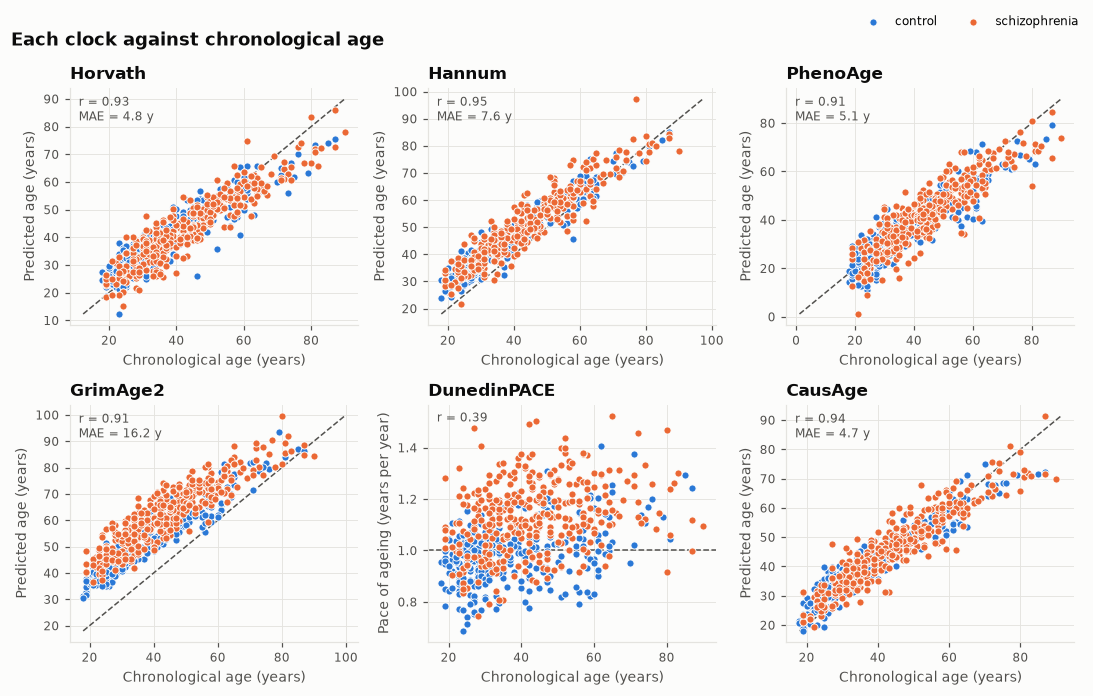

,kind,n,pearson_r,mae_years,median_ae_years,mean_bias_years
clock,,,,,,
Horvath,age,636,0.925,4.807,4.074,0.923
Hannum,age,636,0.947,7.562,7.433,7.019
PhenoAge,age,636,0.906,5.131,4.187,-1.771
GrimAge2,age,636,0.910,16.162,16.053,16.134
DunedinPACE,pace,636,0.393,NaN,NaN,NaN
CausAge,age,636,0.941,4.694,4.242,2.476


In [8]:
metrics = clock_metrics(preds, age, kinds)
metrics.to_csv(out / "clock_metrics.csv")

fig = plot_predicted_vs_age(preds, age, kinds, metrics=metrics, groups=groups, group_order=group_order)
fig.savefig(out / "fig1_predicted_vs_age.png")
plt.show()
metrics

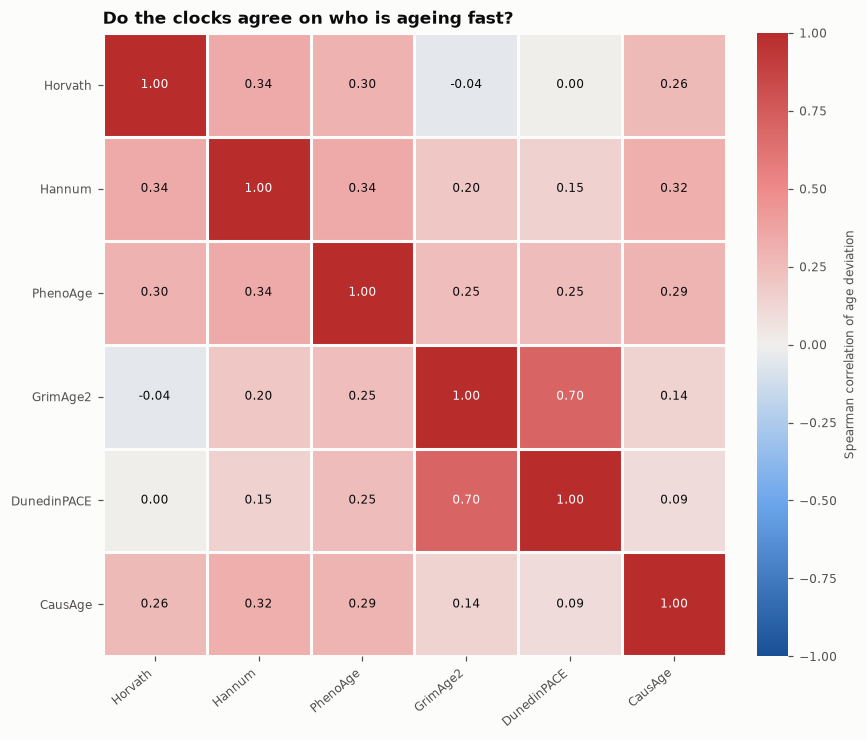

In [9]:
corr = deviation_correlations(dev, method="spearman")
corr.to_csv(out / "age_deviation_correlations.csv")

fig = plot_deviation_heatmap(corr)
fig.savefig(out / "fig2_deviation_correlation.png")
plt.show()

## 6. Schizophrenia vs control

All samples, adjusted for sex. Cohen's d puts clocks with different units (years vs pace) on one scale; q-values are Benjamini-Hochberg across clocks.

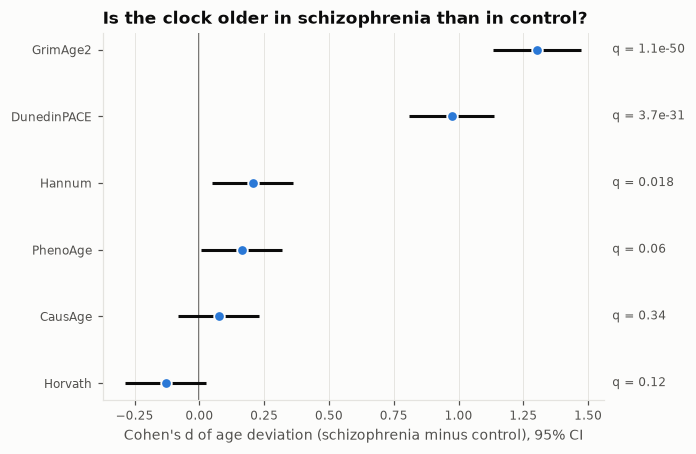

,n_case,n_control,diff,cohens_d,d_ci_low,d_ci_high,diff_adjusted,p_adjusted,q_adjusted
clock,,,,,,,,,
Horvath,332,304,-0.610,-0.130,-0.285,0.026,-0.815,3.680e-02,5.520e-02
Hannum,332,304,0.854,0.206,0.050,0.362,0.319,3.431e-01,3.629e-01
PhenoAge,332,304,0.956,0.162,0.007,0.318,1.258,1.000e-02,2.000e-02
GrimAge2,332,304,6.071,1.303,1.132,1.474,5.623,1.938e-42,1.163e-41
DunedinPACE,332,304,0.119,0.973,0.808,1.137,0.122,9.030e-30,2.709e-29
CausAge,332,304,0.320,0.075,-0.081,0.230,0.324,3.629e-01,3.629e-01


In [10]:
res = compare_groups(dev, groups, case=CASE, control=CONTROL, covariates=sex01.to_frame())
res.to_csv(out / "case_control.csv")

fig = plot_group_forest(res, case=CASE, control=CONTROL)
fig.savefig(out / "fig3_case_control_effect.png")
plt.show()
res[["n_case", "n_control", "diff", "cohens_d", "d_ci_low", "d_ci_high", "diff_adjusted", "p_adjusted", "q_adjusted"]]

## 7. Smoking, blood cells and QC exclusions

Smoking is far more common in schizophrenia and is built into GrimAge, so it is the obvious alternative explanation. Smoking is estimated from methylation (no self-report available), and blood cell proportions are estimated by deconvolution. NK cells are left out (estimated near zero in every sample) and neutrophils are the reference type, since proportions sum to 1.

In [11]:
smoking = gallery.get("SmokingMcCartney", imputation_method=IMPUTATION).predict(model_input)["Predicted"].rename("smoking")
cells = gallery.get("DeconvoluteBlood450K").predict(model_input)
cellcov = cells[["b_cell", "cd4_t_cell", "cd8_t_cell", "monocyte"]]

print("Smoking score by group:")
display(smoking.groupby(groups).agg(["mean", "median", "std"]).round(2).loc[group_order])
print("Mean blood cell proportions by group:")
display(cells.groupby(groups).mean().round(3).loc[group_order])

Smoking score by group:


,mean,median,std
disease,,,
control,3.61,3.33,0.82
schizophrenia,4.91,5.15,1.00


Mean blood cell proportions by group:


,neutrophil,nk_cell,b_cell,cd4_t_cell,cd8_t_cell,monocyte
disease,,,,,,
control,0.586,0.065,0.063,0.144,0.051,0.091
schizophrenia,0.621,0.053,0.061,0.141,0.033,0.091


In [12]:
# Sensitivity of the unadjusted effect (Cohen's d) to the excluded samples
sample_sets = {
    "all": meta.index,
    "without outlier": meta.index.difference(MANUAL_EXCLUDE),
    "QC-passed": qc_pass,
}
d_table = pd.DataFrame({
    name: compare_groups(deviation_table(preds.loc[keep], age.loc[keep]), groups, CASE, CONTROL)["cohens_d"]
    for name, keep in sample_sets.items()
})
print("Cohen's d, schizophrenia minus control:")
d_table.round(2)

Cohen's d, schizophrenia minus control:


,all,without outlier,QC-passed
clock,,,
Horvath,-0.13,-0.13,-0.13
Hannum,0.21,0.21,0.21
PhenoAge,0.16,0.16,0.16
GrimAge2,1.30,1.30,1.30
DunedinPACE,0.97,0.97,0.97
CausAge,0.07,0.07,0.07


In [13]:
# Nested covariate models, on all samples and on QC-passed samples
covariate_sets = {
    "sex": [sex01],
    "sex+smoking": [sex01, smoking],
    "sex+smoking+cells": [sex01, smoking, cellcov],
}
rows = []
for sample_set in ["all", "QC-passed"]:
    keep = sample_sets[sample_set]
    d = deviation_table(preds.loc[keep], age.loc[keep])   # residuals refit on each sample set
    for name, parts in covariate_sets.items():
        r = compare_groups(d, groups, CASE, CONTROL, covariates=pd.concat(parts, axis=1))
        rows.append(r[["n_case", "n_control", "diff_adjusted", "se_adjusted", "p_adjusted"]]
                    .assign(samples=sample_set, model=name).reset_index())

adjusted = pd.concat(rows, ignore_index=True)
adjusted.to_csv(out / "case_control_adjusted.csv", index=False)

print("Difference in age deviation, schizophrenia minus control (years; pace units for DunedinPACE):")
display(adjusted.pivot(index="clock", columns=["samples", "model"], values="diff_adjusted").round(2))
print("p-value:")
display(adjusted.pivot(index="clock", columns=["samples", "model"], values="p_adjusted").map(lambda p: f"{p:.2g}"))

Difference in age deviation, schizophrenia minus control (years; pace units for DunedinPACE):


samples       all                               QC-passed                              
model         sex sex+smoking sex+smoking+cells       sex sex+smoking sex+smoking+cells
clock                                                                                  
CausAge      0.32        0.03             -0.29      0.32        0.03             -0.29
DunedinPACE  0.12        0.04              0.03      0.12        0.04              0.03
GrimAge2     5.62        0.63              0.24      5.62        0.63              0.24
Hannum       0.32        0.52             -0.14      0.32        0.52             -0.14
Horvath     -0.82       -0.22             -0.14     -0.82       -0.22             -0.14
PhenoAge     1.26        0.77              0.01      1.26        0.77              0.01

p-value:


samples          all                               QC-passed                              
model            sex sex+smoking sex+smoking+cells       sex sex+smoking sex+smoking+cells
clock                                                                                     
CausAge         0.36        0.94               0.5      0.36        0.94               0.5
DunedinPACE    9e-30       6e-05            0.0016     9e-30       6e-05            0.0016
GrimAge2     1.9e-42        0.03               0.4   1.9e-42        0.03               0.4
Hannum          0.34         0.2              0.72      0.34         0.2              0.72
Horvath        0.037        0.64              0.78     0.037        0.64              0.78
PhenoAge        0.01        0.19              0.99      0.01        0.19              0.99

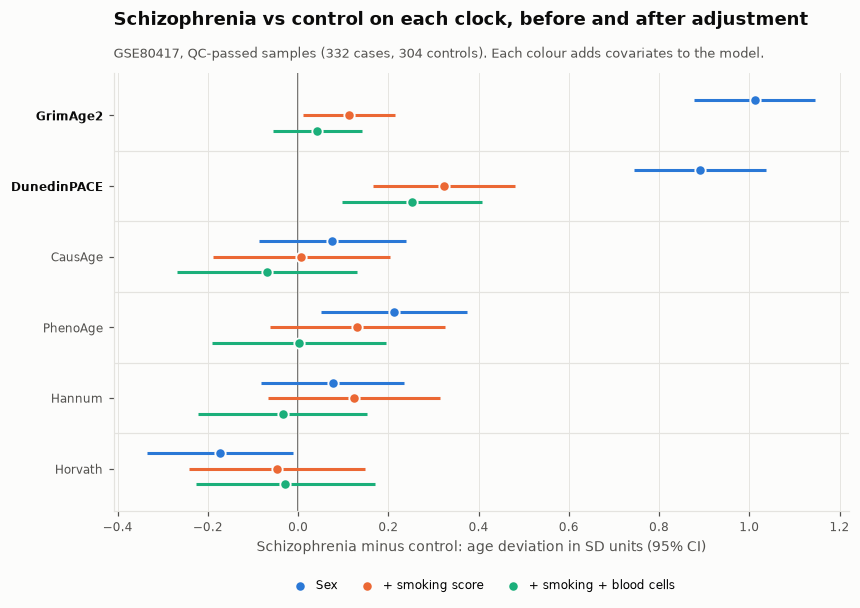

In [14]:
# Figure 4: the same models on QC-passed samples, in SD units so years and pace are comparable
d_sd = deviation_table(preds.loc[qc_pass], age.loc[qc_pass])
d_sd = d_sd / d_sd.std()
labels = {"sex": "Sex", "sex+smoking": "+ smoking score", "sex+smoking+cells": "+ smoking + blood cells"}
effects = {labels[name]: compare_groups(d_sd, groups, CASE, CONTROL, covariates=pd.concat(parts, axis=1))
           for name, parts in covariate_sets.items()}

order = [c for c in ["Horvath", "Hannum", "PhenoAge", "CausAge", "DunedinPACE", "GrimAge2"] if c in d_sd.columns]
n_case, n_ctrl = (int(v) for v in effects["Sex"].loc[order[0], ["n_case", "n_control"]])

fig = plot_adjustment_effect(
    effects, order,
    title="Schizophrenia vs control on each clock, before and after adjustment",
    subtitle=f"{DATASET}, QC-passed samples ({n_case} cases, {n_ctrl} controls). Each colour adds covariates to the model.",
    xlabel="Schizophrenia minus control: age deviation in SD units (95% CI)",
    highlight={"GrimAge2", "DunedinPACE"},
)
fig.savefig(out / "fig4_adjustment_effect.png")
plt.show()

## 9. Probe-set sensitivity

GSE84727 was deposited without about 65,000 probes, among them 18% of GrimAge2's CpGs and 14% of DunedinPACE's. Here the clocks run a second time on this dataset restricted to GSE84727's probes, with the missing CpGs filled from the reference exactly as they are in GSE84727.

- **Agreement:** correlation between the all-probe and restricted estimates, and between their age deviations. The SD ratio below 1 means the restricted clock spreads people less.
- **Effect:** the schizophrenia effect with both probe sets, in SD units of the *all-probe* age deviation, so any shrinkage shows.

A clock that changes here is not comparable across the three cohorts as GSE84727 was deposited.

In [15]:
if SENSITIVITY_PROBES and SENSITIVITY_PROBES != DATASET:
    restricted = subset_cpgs(model_input, probe_ids(SENSITIVITY_PROBES))
    removed = model_input.dnam.shape[0] - restricted.dnam.shape[0]
    print(f"Restricted to {SENSITIVITY_PROBES}'s probes: {removed:,} of {model_input.dnam.shape[0]:,} model CpGs removed")

    run_r = run_clocks(restricted, clock_names, imputation=IMPUTATION)
    for label, err in run_r.failed.items():
        print(f"  {label:<12} FAILED  {err[:160]}")
    smoking_r = gallery.get("SmokingMcCartney", imputation_method=IMPUTATION).predict(restricted)["Predicted"].rename("smoking")

    both = [c for c in preds.columns if c in run_r.predictions.columns]
    full_p, restr_p = preds.loc[qc_pass, both], run_r.predictions.loc[qc_pass, both]
    dev_full = deviation_table(full_p, age.loc[qc_pass])
    dev_restr = deviation_table(restr_p, age.loc[qc_pass])
    agreement = pd.DataFrame({
        "r, estimate": full_p.corrwith(restr_p),
        "r, age deviation": dev_full.corrwith(dev_restr),
        "mean shift": (restr_p - full_p).mean(),
        "SD ratio, age deviation": dev_restr.std() / dev_full.std(),
    })
    agreement.to_csv(out / f"probe_sensitivity_agreement_{SENSITIVITY_PROBES}.csv")
    display(agreement.round(3))
else:
    print("Skipped: no sensitivity probe set, or this is that dataset")

Restricted to GSE84727's probes: 532 of 22,975 model CpGs removed


,"r, estimate","r, age deviation",mean shift,"SD ratio, age deviation"
Horvath,0.998,0.985,-0.589,0.983
Hannum,0.999,0.991,0.427,0.950
PhenoAge,1.000,0.998,-0.621,0.990
GrimAge2,0.996,0.984,-1.321,0.838
DunedinPACE,0.981,0.979,0.000,0.890
CausAge,0.996,0.967,-0.041,0.961


Schizophrenia minus control, SD units of the all-probe age deviation:


all probes                                     GSE84727 probes only                                    
                      sex              sex+smoking                             sex              sex+smoking           
            diff_adjusted p_adjusted diff_adjusted p_adjusted        diff_adjusted p_adjusted diff_adjusted p_adjusted
clock                                                                                                                 
Horvath            -0.173      0.037        -0.047      0.635               -0.144      0.077        -0.022      0.823
Hannum              0.077      0.343         0.124      0.201                0.085      0.269         0.137      0.139
PhenoAge            0.213      0.010         0.131      0.186                0.198      0.016         0.114      0.247
GrimAge2            1.012      0.000         0.113      0.030                0.818      0.000         0.111      0.023
DunedinPACE         0.891      0.000         0.324      0.000                0.741      0.000         0.376      0.000
CausAge             0.076      0.363         0.007      0.945                0.049      0.543        -0.026      0.787

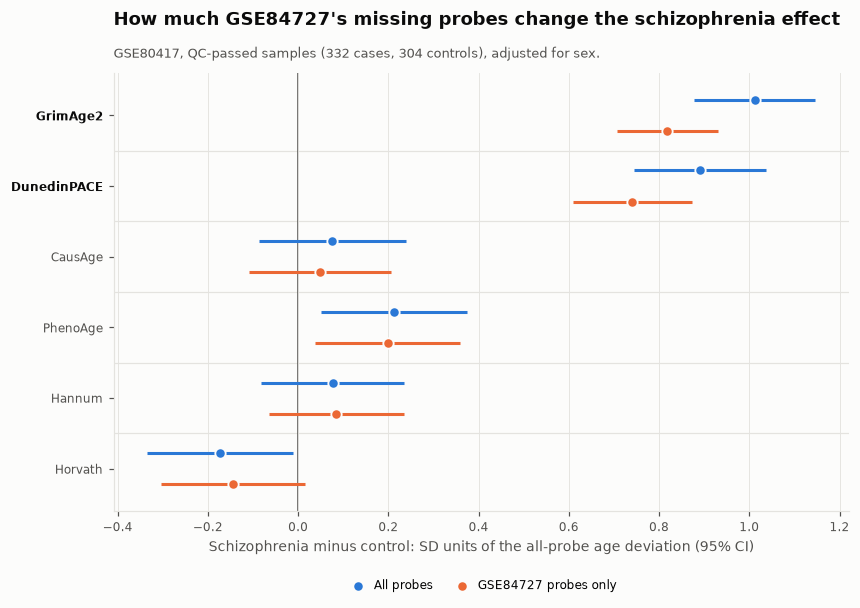

In [16]:
if SENSITIVITY_PROBES and SENSITIVITY_PROBES != DATASET:
    scale = dev_full.std()  # both in SD units of the all-probe deviation, so shrinkage shows
    probe_label = f"{SENSITIVITY_PROBES} probes only"
    sens = {}
    for probes, d, smk in [("all probes", dev_full / scale, smoking), (probe_label, dev_restr / scale, smoking_r)]:
        for model, cov in [("sex", sex01.to_frame()), ("sex+smoking", pd.concat([sex01, smk], axis=1))]:
            sens[(probes, model)] = compare_groups(d, groups, CASE, CONTROL, covariates=cov)

    sens_tbl = pd.concat({k: v[["diff_adjusted", "p_adjusted"]] for k, v in sens.items()}, axis=1)
    sens_tbl.to_csv(out / f"probe_sensitivity_effects_{SENSITIVITY_PROBES}.csv")
    print("Schizophrenia minus control, SD units of the all-probe age deviation:")
    display(sens_tbl.round(3))

    order = [c for c in ["Horvath", "Hannum", "PhenoAge", "CausAge", "DunedinPACE", "GrimAge2"] if c in both]
    n_case, n_ctrl = (int(v) for v in sens[("all probes", "sex")].loc[order[0], ["n_case", "n_control"]])
    fig = plot_adjustment_effect(
        {"All probes": sens[("all probes", "sex")], probe_label: sens[(probe_label, "sex")]}, order,
        title=f"How much {SENSITIVITY_PROBES}'s missing probes change the schizophrenia effect",
        subtitle=f"{DATASET}, QC-passed samples ({n_case} cases, {n_ctrl} controls), adjusted for sex.",
        xlabel="Schizophrenia minus control: SD units of the all-probe age deviation (95% CI)",
        highlight={"GrimAge2", "DunedinPACE"},
    )
    fig.savefig(out / f"fig5_probe_sensitivity_{SENSITIVITY_PROBES}.png")
    plt.show()

## 10. Environment

In [17]:
freeze = subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout
(out / "environment.txt").write_text(f"dataset={DATASET}\nimputation={IMPUTATION}\n\n" + freeze)
print("Wrote", sorted(p.name for p in out.iterdir() if p.name != ".gitkeep"))

Wrote ['age_deviation_correlations.csv', 'age_deviation_per_sample.csv', 'case_control.csv', 'case_control_adjusted.csv', 'clock_benchmark_GSE80417.ipynb', 'clock_metrics.csv', 'environment.txt', 'fig1_predicted_vs_age.png', 'fig2_deviation_correlation.png', 'fig3_case_control_effect.png', 'fig4_adjustment_effect.png', 'fig5_probe_sensitivity_GSE84727.png', 'probe_sensitivity_agreement_GSE84727.csv', 'probe_sensitivity_effects_GSE84727.csv']
